# Results Analysis

Read pre-computed `.pkl` result files from `run_elevation_sim.py` and reproduce
every plot from `urban_rician_sim.ipynb`.

**No Sionna / DrJIT / GPU required.**

## 1 — Imports

In [1]:
import os, sys, pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
%matplotlib inline

SCRIPT_DIR = os.path.abspath(".")
sys.path.insert(0, SCRIPT_DIR)

from checkpoint_utils import load_all_results
from plot_utils import (
    plot_spatial_stats, plot_los_map, plot_cdfs,
    plot_angle_comparison, plot_cir,
    plot_metrics_vs_elevation_multi_config,
    export_metrics_vs_elevation_multi_config_csv,
    print_summary,
)

print("Imports OK.")

Imports OK.


## 2 — Configuration

Set paths and parameters here before running.

In [4]:
# ── Result directories ────────────────────────────────────────────────────────
BASE_DIR     = "./urban_env_results_base_cell"   # baseline (no iono/atm)
IA_DIR       = "./urban_env_results_atm_iono_cell"  # with iono+atm

# Multi-config directories for Fig 6 (polarisation × slant comparison)
# OUTPUT_DIRS = {
#     "VV 1.9GHz":   "./results_1.9GHz_VV",
#     "VV 6GHz":  "./results_6GHz_VV",
#     "VV 11GHz": "./results_11GHz_VV",
#     "HH 1.9GHz":   "./results_1.9GHz_HH",
#     "HH 6GHz":  "./results_6GHz_HH",
#     "HH 11GHz": "./results_11GHz_HH",
#     "RHCP 1.9GHz": "./results_1.9GHz_circ",
#     "RHCP 6GHz":  "./results_6GHz_circ",
#     "RHCP 11GHz": "./results_11GHz_circ",
# }

OUTPUT_DIRS = {
    
    "RHCP": "./results_sat_circ",
    "VV":   "./results_sat_VV",
    "HH":  "./results_sat_HH",
}

# Elevation angles present in result files
ELEVATION_ANGLES = [9, 20, 30, 40, 49, 60, 69, 80, 89]

# Output directory for saved figures
FIG_DIR = "./figures_analysis"
os.makedirs(FIG_DIR, exist_ok=True)

# RF parameters (must match the simulation that produced the results)
FREQUENCY = 1.9e9   # Hz

# RX placement cache + serialised simulation config (written by urban_rician_sim.ipynb)
RX_POSITIONS_FILE = "./rx_positions.pkl"
CONFIG_FILE       = "./sim_config.json"

## 3 — Load Results

In [4]:
all_results = load_all_results(BASE_DIR, ELEVATION_ANGLES)

if not all_results:
    print("No results found — check BASE_DIR and ELEVATION_ANGLES.")
else:
    print(f"Loaded {len(all_results)} elevation angle(s) from BASE_DIR:")
    for _angle, _res in sorted(all_results.items()):
        _plos = np.mean(_res["los_probability"]) * 100
        n_raw = len(_res.get("raw_results", []))
        print(f"  {_angle:.0f}°  N_RX={_res['n_rx_positions']:,}  "
              f"P(LoS)={_plos:.1f}%  raw_results={n_raw}")

[checkpoint] Loaded results  elev=10.0°  n_rx=20000
[checkpoint] Loaded results  elev=20.0°  n_rx=20000
[checkpoint] Loaded results  elev=30.0°  n_rx=20000
[checkpoint] Loaded results  elev=40.0°  n_rx=20000
[checkpoint] Loaded results  elev=50.0°  n_rx=20000
[checkpoint] Loaded results  elev=60.0°  n_rx=20000
[checkpoint] Loaded results  elev=70.0°  n_rx=20000
[checkpoint] Loaded results  elev=80.0°  n_rx=20000
Loaded 8 elevation angle(s) from BASE_DIR:
  10°  N_RX=20,000  P(LoS)=12.4%  raw_results=50
  20°  N_RX=20,000  P(LoS)=26.0%  raw_results=50
  30°  N_RX=20,000  P(LoS)=35.8%  raw_results=50
  40°  N_RX=20,000  P(LoS)=45.7%  raw_results=50
  50°  N_RX=20,000  P(LoS)=55.3%  raw_results=50
  60°  N_RX=20,000  P(LoS)=64.6%  raw_results=50
  70°  N_RX=20,000  P(LoS)=75.0%  raw_results=50
  80°  N_RX=20,000  P(LoS)=86.4%  raw_results=50


## 4 — Summary Statistics per Elevation

In [5]:
for _angle in sorted(all_results.keys()):
    print_summary(all_results[_angle])

    _res  = all_results[_angle]
    _n    = _res["n_rx_positions"]
    _has_los   = np.array(_res["los_probability"], dtype=bool)
    _P_los_arr = np.array(_res.get("P_los") or ([0.0] * _n))
    _P_spec    = np.array(_res.get("P_specular",    [0.0] * _n))
    _P_diff    = np.array(_res.get("P_diffuse",     [0.0] * _n))
    _P_diffr   = np.array(_res.get("P_diffraction", [0.0] * _n))
    _P_refr    = np.array(_res.get("P_refraction",  [0.0] * _n))
    _P_nlos    = np.array(_res.get("P_nlos",        [0.0] * _n))

    _P_los_f  = _P_los_arr[_has_los]
    _P_spec_f = _P_spec[_has_los]
    _P_diff_f = _P_diff[_has_los]
    _P_diffr_f= _P_diffr[_has_los]
    _P_refr_f = _P_refr[_has_los]
    _P_nlos_f = _P_nlos[_has_los]
    _n_los    = int(np.sum(_has_los))

    _K_ens    = float(np.mean(_P_los_f)) / (float(np.mean(_P_nlos_f)) + 1e-300)
    _K_ens_dB = 10.0 * np.log10(_K_ens + 1e-12)
    _P_total  = _P_los_f + _P_spec_f + _P_diff_f + _P_diffr_f + _P_refr_f + 1e-300
    _mean_tot = float(np.mean(_P_total))

    print(f"  Ensemble K (LoS only, n={_n_los:,}): {_K_ens_dB:+.2f} dB")
    print(f"  Power breakdown (LoS RX, ratio-of-means):")
    for lbl, arr in [("P_los", _P_los_f), ("P_specular", _P_spec_f),
                     ("P_diffuse", _P_diff_f), ("P_diffraction", _P_diffr_f),
                     ("P_refraction", _P_refr_f)]:
        print(f"    {lbl:<14}: {float(np.mean(arr))/_mean_tot*100:6.2f} %")
    print()

══════════════════════════════════════════════════════════════════════
  CHANNEL STATISTICS  —  Elev = 10°  |  N_RX = 20,000
══════════════════════════════════════════════════════════════════════

  LoS Statistics:
  LoS positions                     2,472  (12.4 %)
  NLOS positions                    17,528  (87.6 %)

  Rician K-Factor:
    K_mean [dB]                     +0.93 dB  (linear 1.2388)

  RMS Delay Spread:
    τ_rms LoS [ns]                  mean=60.8052  median=45.0937  std=59.6356  ns

  RMS Delay Spread  (NLOS receivers, n=17,528):
    τ_rms NLOS [ns]                 mean=277.6845  median=278.0172  std=141.4118  ns
══════════════════════════════════════════════════════════════════════
  Ensemble K (LoS only, n=2,472): +4.30 dB
  Power breakdown (LoS RX, ratio-of-means):
    P_los         :  72.91 %
    P_specular    :  22.99 %
    P_diffuse     :   2.52 %
    P_diffraction :   1.58 %
    P_refraction  :   0.00 %

═════════════════════════════════════════════════════════

## 5 — Spatial Heat-Maps (K-Factor & Delay Spread)

One figure per elevation angle.

In [ ]:
for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_spatial_stats(
        nominal_rx_positions = _res["nominal_rx_positions"],
        K_power_ratio        = _res["K_power_ratio"],
        tau_rms_mean_s       = _res["tau_rms_mean_s"],
        los_probability      = _res["los_probability"],
        elevation_deg        = _angle,
        frequency            = _res.get("frequency", FREQUENCY),
        slant_dist_m         = _res.get("slant_dist_m", 500_000),
        cfg_label            = f"elev={int(_angle)}°",
    )
    _fname = os.path.join(FIG_DIR, f"spatial_stats_elev{int(_angle):03d}deg.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved -> {_fname}")

## 6 — LoS / NLOS Maps

In [ ]:
for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_los_map(
        nominal_rx_positions = _res["nominal_rx_positions"],
        los_probability      = _res["los_probability"],
        elevation_deg        = _angle,
    )
    _fname = os.path.join(FIG_DIR, f"los_map_elev{int(_angle):03d}deg.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved -> {_fname}")

## 7 — CDFs (K-Factor & Delay Spread)

In [ ]:
for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_cdfs(
        K_power_ratio   = _res["K_power_ratio"],
        tau_rms_mean_s  = _res["tau_rms_mean_s"],
        los_probability = _res["los_probability"],
        elevation_deg   = _angle,
    )
    _fname = os.path.join(FIG_DIR, f"cdfs_elev{int(_angle):03d}deg.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved -> {_fname}")

## 8 — Cross-Angle Comparison

In [ ]:
if len(all_results) >= 2:
    fig = plot_angle_comparison(all_results)
    _fname = os.path.join(FIG_DIR, "angle_comparison.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved -> {_fname}")
else:
    print("Need at least 2 elevation angles.")

## 9 — Ionospheric / Atmospheric Correction Comparison

Compares baseline vs iono+atm for a single elevation angle.

In [ ]:
# ── Config: pick which elevation angle to inspect ────────────────────────────
COMPARE_ELEV = 30   # degrees — must exist in both BASE_DIR and IA_DIR

def _load_pkl(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def _to_db(x):
    return 10 * np.log10(np.clip(x, 1e-20, None))

def _ecdf(x):
    s = np.sort(x[np.isfinite(x)])
    return s, np.arange(1, len(s) + 1) / len(s)

def _arr(d, key):
    return np.asarray(d[key], dtype=float)

_tag  = f"results_elev{COMPARE_ELEV:03d}deg.pkl"
_b_path = os.path.join(BASE_DIR, _tag)
_i_path = os.path.join(IA_DIR,   _tag)

if not os.path.exists(_b_path) or not os.path.exists(_i_path):
    print(f"Missing file(s): {_b_path} or {_i_path}")
else:
    base = _load_pkl(_b_path)
    ia   = _load_pkl(_i_path)

    K_base = _arr(base, "K_power_ratio");  Kdb_b = _to_db(K_base)
    K_ia   = _arr(ia,   "K_power_ratio");  Kdb_i = _to_db(K_ia)

    los_mask  = _arr(base, "P_los") > 0
    _n_total, _n_los = int(los_mask.size), int(los_mask.sum())
    Kdb_b_los = Kdb_b[los_mask];  Kdb_i_los = Kdb_i[los_mask]

    P_tot_b = _to_db(_arr(base, "P_los") + _arr(base, "P_nlos"))
    P_tot_i = _to_db(_arr(ia,   "P_los") + _arr(ia,   "P_nlos"))
    dP_db   = P_tot_i - P_tot_b

    tau_b = _arr(base, "tau_rms_mean_s") * 1e9
    tau_i = _arr(ia,   "tau_rms_mean_s") * 1e9
    vtec  = _arr(ia, "vtec_sample") if "vtec_sample" in ia else np.zeros(len(K_ia))
    rx_idx = np.arange(len(K_base))

    freq_ghz = base.get("frequency", 1.9e9) / 1e9
    elev     = base.get("elevation_deg", COMPARE_ELEV)

    COLORS = {"base": "#4C72B0", "ia": "#DD8452", "delta": "#55A868"}

    fig = plt.figure(figsize=(15, 10), constrained_layout=True)
    gs  = GridSpec(2, 3, figure=fig)
    fig.suptitle(f"Iono/Atm vs Baseline — {freq_ghz:.2f} GHz, el={elev}°",
                 fontsize=14, fontweight="bold")

    # K-factor profile (P5–P95, LoS only)
    _valid  = np.isfinite(Kdb_b_los) & np.isfinite(Kdb_i_los)
    _order  = np.argsort(Kdb_b_los[_valid])
    _Kb_s   = Kdb_b_los[_valid][_order]
    _Ki_s   = Kdb_i_los[_valid][_order]
    _pct    = np.linspace(0, 100, _order.size)
    _p5, _p95 = np.nanpercentile(_Kb_s, 5), np.nanpercentile(_Kb_s, 95)
    _pad    = (_p95 - _p5) * 0.05
    _view   = (_Kb_s >= _p5 - _pad) & (_Kb_s <= _p95 + _pad)
    _med_b  = np.nanmedian(Kdb_b_los);  _med_i = np.nanmedian(Kdb_i_los)

    ax1 = fig.add_subplot(gs[0, :2])
    ax1.plot(_pct[_view], _Kb_s[_view], color=COLORS["base"], lw=1.5,
             label=f"Baseline  (median = {_med_b:.1f} dB)")
    ax1.plot(_pct[_view], _Ki_s[_view], color=COLORS["ia"],   lw=1.5, alpha=0.8,
             label=f"Iono+Atm  (median = {_med_i:.1f} dB)")
    ax1.axhline(_med_b, color=COLORS["base"], ls="--", lw=1.0, alpha=0.6)
    ax1.axhline(_med_i, color=COLORS["ia"],   ls="--", lw=1.0, alpha=0.6)
    ax1.set_xlabel("LoS RX percentile (sorted by baseline K)  [%]")
    ax1.set_ylabel("K-factor [dB]")
    ax1.set_title(f"K-factor profile — LoS positions only  ({_n_los:,} / {_n_total:,} RX, P5–P95)")
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2 = fig.add_subplot(gs[0, 2])
    xb, yb = _ecdf(Kdb_b_los); xi, yi = _ecdf(Kdb_i_los)
    ax2.plot(xb, yb, color=COLORS["base"], lw=2, label="Baseline")
    ax2.plot(xi, yi, color=COLORS["ia"],   lw=2, label="Iono + Atm")
    for p in [0.1, 0.5, 0.9]:
        ax2.axhline(p, color="grey", ls=":", lw=0.6)
    ax2.set_xlabel("K-factor [dB]"); ax2.set_ylabel("CDF")
    ax2.set_title("K-factor CDF  (LoS only)"); ax2.legend(); ax2.grid(alpha=0.3)

    ax3 = fig.add_subplot(gs[1, :2])
    ax3.bar(rx_idx, dP_db, color=np.where(dP_db < 0, COLORS["ia"], COLORS["delta"]),
            alpha=0.7, width=1.0)
    ax3.axhline(0, color="black", lw=0.8)
    ax3.axhline(np.nanmean(dP_db), color="red", ls="--", lw=1.5,
                label=f"mean Δ = {np.nanmean(dP_db):+.2f} dB")
    ax3.set_xlabel("RX position index"); ax3.set_ylabel("ΔP [dB]  (iono+atm − baseline)")
    ax3.set_title("Per-RX channel power change due to iono/atm corrections")
    ax3.legend(); ax3.grid(alpha=0.3, axis="y")

    ax4 = fig.add_subplot(gs[1, 2])
    sc  = ax4.scatter(tau_b, tau_i, c=vtec, cmap="plasma", s=20, alpha=0.7, edgecolors="none")
    lim = [0, max(tau_b.max(), tau_i.max()) * 1.05]
    ax4.plot(lim, lim, "k--", lw=1, label="y = x")
    cb  = fig.colorbar(sc, ax=ax4); cb.set_label("VTEC sample [TECU]")
    ax4.set_xlabel("τ_rms baseline [ns]"); ax4.set_ylabel("τ_rms iono+atm [ns]")
    ax4.set_title("RMS delay spread: baseline vs iono+atm")
    ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

    _fname = os.path.join(FIG_DIR, f"iono_atm_comparison_elev{int(elev):03d}deg.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved -> {_fname}")

    print(f"LoS positions : {_n_los:,} / {_n_total:,}  ({100*_n_los/_n_total:.1f}%)")
    print(f"K mean  baseline={np.nanmean(Kdb_b_los):.2f} dB   "
          f"iono+atm={np.nanmean(Kdb_i_los):.2f} dB   "
          f"Δ={np.nanmean(Kdb_i_los)-np.nanmean(Kdb_b_los):+.2f} dB  (LoS only)")
    print(f"ΔP mean   {np.nanmean(dP_db):+.3f} dB    std {np.nanstd(dP_db):.3f} dB")
    print(f"τ_rms  baseline={np.nanmean(tau_b):.3f} ns   iono+atm={np.nanmean(tau_i):.3f} ns")

## 10 — K-Factor vs Elevation Angle (Baseline vs Iono+Atm)

In [ ]:
def _load(p):
    with open(p, "rb") as f: return pickle.load(f)

_elev_results = []
for el in ELEVATION_ANGLES:
    _tag = f"results_elev{el:03d}deg.pkl"
    _bp  = os.path.join(BASE_DIR, _tag)
    _ip  = os.path.join(IA_DIR,   _tag)
    if not (os.path.exists(_bp) and os.path.exists(_ip)):
        print(f"  elev={el}° — missing file, skipping")
        continue
    b  = _load(_bp);  ia = _load(_ip)
    los = np.asarray(b["P_los"], dtype=float) > 0
    Kb  = 10*np.log10(np.clip(np.asarray(b["K_power_ratio"],  float), 1e-20, None))[los]
    Ki  = 10*np.log10(np.clip(np.asarray(ia["K_power_ratio"], float), 1e-20, None))[los]
    dP  = (10*np.log10(np.clip(np.asarray(ia["P_los"],float)+np.asarray(ia["P_nlos"],float),1e-20,None))
           - 10*np.log10(np.clip(np.asarray(b["P_los"],float)+np.asarray(b["P_nlos"],float),1e-20,None)))
    _elev_results.append({
        "el": el,
        "plos":    100 * los.sum() / los.size,
        "K_med_b": float(np.nanmedian(Kb)),
        "K_med_i": float(np.nanmedian(Ki)),
        "dK":      float(np.nanmedian(Ki) - np.nanmedian(Kb)),
        "dP_mean": float(np.nanmean(dP)),
    })

if _elev_results:
    el_arr   = np.array([r["el"]      for r in _elev_results])
    plos_arr = np.array([r["plos"]    for r in _elev_results])
    Kb_arr   = np.array([r["K_med_b"] for r in _elev_results])
    Ki_arr   = np.array([r["K_med_i"] for r in _elev_results])
    dK_arr   = np.array([r["dK"]      for r in _elev_results])
    dP_arr   = np.array([r["dP_mean"] for r in _elev_results])

    COLORS = {"base": "#4C72B0", "ia": "#DD8452", "plos": "#55A868", "zero": "grey"}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    fig.suptitle("K-Factor vs Elevation Angle — LoS Positions Only  (Baseline vs Iono+Atm)",
                 fontsize=13, fontweight="bold")

    ax1.plot(el_arr, Kb_arr, "o-",  color=COLORS["base"], lw=2, ms=6, label="Baseline")
    ax1.plot(el_arr, Ki_arr, "s--", color=COLORS["ia"],   lw=2, ms=6, label="Iono + Atm")
    ax1.set_xlabel("Elevation angle [°]"); ax1.set_ylabel("K-factor median [dB]  (LoS only)")
    ax1.set_xticks(el_arr); ax1.grid(alpha=0.3)
    ax1r = ax1.twinx()
    ax1r.bar(el_arr, plos_arr, width=4, alpha=0.18, color=COLORS["plos"], label="LoS %")
    ax1r.set_ylabel("LoS probability [%]", color=COLORS["plos"])
    ax1r.tick_params(axis="y", labelcolor=COLORS["plos"]); ax1r.set_ylim(0, 110)
    lines1, labs1 = ax1.get_legend_handles_labels()
    lines2, labs2 = ax1r.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labs1 + labs2, loc="lower right")
    ax1.set_title("K-factor median (LoS only) and LoS probability")

    ax2b = ax2.twinx()
    ax2.bar(el_arr - 1.2, dK_arr, width=2.4, color=COLORS["base"], alpha=0.7, label="ΔK [dB]  (LoS only)")
    ax2b.plot(el_arr, dP_arr, "D-", color=COLORS["ia"], lw=2, ms=6, label="ΔP mean [dB]  (all RX)")
    ax2.axhline(0, color=COLORS["zero"], lw=0.8, ls="--")
    ax2b.axhline(0, color=COLORS["zero"], lw=0.8, ls="--")
    ax2.set_xlabel("Elevation angle [°]"); ax2.set_ylabel("ΔK [dB]", color=COLORS["base"])
    ax2b.set_ylabel("ΔP mean [dB]", color=COLORS["ia"])
    ax2.tick_params(axis="y", labelcolor=COLORS["base"])
    ax2b.tick_params(axis="y", labelcolor=COLORS["ia"])
    ax2.set_xticks(el_arr); ax2.grid(alpha=0.3, axis="x")
    lines3, labs3 = ax2.get_legend_handles_labels()
    lines4, labs4 = ax2b.get_legend_handles_labels()
    ax2.legend(lines3 + lines4, labs3 + labs4, loc="lower left")
    ax2.set_title("ΔK and ΔP: Iono+Atm minus Baseline")

    _fname = os.path.join(FIG_DIR, "k_vs_elevation_base_vs_ia.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved -> {_fname}")

    print(f"{'el':>4}  {'LoS%':>6}  {'K_base':>7}  {'K_ia':>7}  {'dK':>6}  {'dP_mean':>8}")
    for r in _elev_results:
        print(f"{r['el']:>4}  {r['plos']:>6.1f}  {r['K_med_b']:>7.2f}  "
              f"{r['K_med_i']:>7.2f}  {r['dK']:>+6.2f}  {r['dP_mean']:>+8.3f}")

## 11 — Fresnel Coefficients & K-Factor vs Elevation (Material Comparison)

Plots ITU-R P.2040-1 Fresnel |Γ| alongside the simulated K-factor from two result sets.

In [ ]:
# ── Material parameters (ITU-R P.2040-1) ────────────────────────────────────
freq_GHz = FREQUENCY / 1e9
eps_0    = 8.854187817e-12
omega    = 2 * np.pi * FREQUENCY

def _itu_mat(a, b, c, d):
    er = a * freq_GHz**b
    sg = c * freq_GHz**d
    return er - 1j * sg / (omega * eps_0)

eps_conc = _itu_mat(5.24,  0.0, 0.0462, 0.7822)   # concrete
eps_gr   = _itu_mat(15.0, -0.1, 0.035,  1.63)     # medium dry ground

theta_deg = np.linspace(0.1, 90.0, 2000)
theta     = np.deg2rad(theta_deg)

def _fresnel(eps_c):
    D   = np.sqrt(eps_c - np.cos(theta)**2)
    Gte = (np.sin(theta) - D) / (np.sin(theta) + D)
    Gtm = (eps_c * np.sin(theta) - D) / (eps_c * np.sin(theta) + D)
    return np.abs(Gte), np.abs(Gtm), theta_deg[np.argmin(np.abs(Gtm))]

mag_TE_c, mag_TM_c, brew_c = _fresnel(eps_conc)
mag_TE_g, mag_TM_g, brew_g = _fresnel(eps_gr)

# ── K-factor: concrete from simulation; ground estimated via Fresnel scaling ──
# All simulation runs used itu_concrete. The ground estimate scales only the
# specular-reflection power by |Γ_TM_ground|² / |Γ_TM_concrete|² at each
# elevation angle; LoS, diffuse, diffraction, and refraction are unchanged.

def _fresnel_TM_at(eps_c, el_deg):
    """Return |Γ_TM| at a single elevation angle."""
    t = np.deg2rad(el_deg)
    D = np.sqrt(eps_c - np.cos(t) ** 2)
    return abs((eps_c * np.sin(t) - D) / (eps_c * np.sin(t) + D))

def _mean_K_dB_concrete(result_dir, elevs):
    """K-factor (ratio-of-means) from simulation data."""
    vals = []
    for el in elevs:
        p = os.path.join(result_dir, f"results_elev{int(el):03d}deg.pkl")
        if not os.path.exists(p):
            vals.append(np.nan); continue
        with open(p, "rb") as f: d = pickle.load(f)
        P_los  = float(np.mean(np.asarray(d.get("P_los",  [0.0]), float)))
        P_nlos = float(np.mean(np.asarray(d.get("P_nlos", [0.0]), float)))
        vals.append(10 * np.log10(P_los / (P_nlos + 1e-30) + 1e-30))
    return np.array(vals)

def _mean_K_dB_ground_est(result_dir, elevs, eps_c, eps_g):
    """Estimate K-factor for ground material using Fresnel-ratio scaling of P_specular."""
    vals = []
    for el in elevs:
        p = os.path.join(result_dir, f"results_elev{int(el):03d}deg.pkl")
        if not os.path.exists(p):
            vals.append(np.nan); continue
        with open(p, "rb") as f: d = pickle.load(f)
        def _m(key): return float(np.mean(np.asarray(d.get(key, [0.0]), float)))
        P_los   = _m("P_los")
        P_spec  = _m("P_specular")
        P_diff  = _m("P_diffuse")
        P_diffr = _m("P_diffraction")
        P_refr  = _m("P_refraction")
        Gc = _fresnel_TM_at(eps_c, el)
        Gg = _fresnel_TM_at(eps_g, el)
        scale = (Gg / (Gc + 1e-12)) ** 2
        P_nlos_gr = P_spec * scale + P_diff + P_diffr + P_refr
        vals.append(10 * np.log10(P_los / (P_nlos_gr + 1e-30) + 1e-30))
    return np.array(vals)

angles = np.array(sorted(all_results.keys()))
K_conc = _mean_K_dB_concrete(BASE_DIR, angles)
K_gr   = _mean_K_dB_ground_est(BASE_DIR, angles, eps_conc, eps_gr)

fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
fig.suptitle(
    f"ITU Concrete (\u03b5r={eps_conc.real:.2f}) vs Med. Dry Ground (\u03b5r={eps_gr.real:.2f})  |  f={freq_GHz:.2f} GHz",
    fontsize=11
)

ax = axes[0]
ax.plot(theta_deg, mag_TE_c, "steelblue", lw=2, label="TE (H-pol) Concrete")
ax.plot(theta_deg, mag_TM_c, "blue",      lw=2, label="TM (V-pol) Concrete")
ax.axvline(brew_c, color="steelblue", ls="--", lw=1.4, label=f"Brewster Concrete \u2248 {brew_c:.1f}\u00b0")
ax.plot(theta_deg, mag_TE_g, "tomato",    lw=2, label="TE (H-pol) Med. Dry Ground")
ax.plot(theta_deg, mag_TM_g, "red",       lw=2, label="TM (V-pol) Med. Dry Ground")
ax.axvline(brew_g, color="tomato",    ls="--", lw=1.4, label=f"Brewster Ground  \u2248 {brew_g:.1f}\u00b0")
ax.set_ylabel("|\u0393|  \u2014  Reflection Magnitude"); ax.set_ylim(0, 1.05)
ax.set_title("Fresnel Reflection Coefficients vs Elevation Angle")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(angles, K_conc, "o-",  color="blue",  lw=2, label="Concrete (simulated)")
ax.plot(angles, K_gr,   "s--", color="red",   lw=2, label="Med. Dry Ground (Fresnel-scaled estimate)")
ax.axvline(brew_c, color="steelblue", ls="--", lw=1.4, label=f"Brewster Concrete \u2248 {brew_c:.1f}\u00b0")
ax.axvline(brew_g, color="tomato",    ls="--", lw=1.4, label=f"Brewster Ground   \u2248 {brew_g:.1f}\u00b0")
ax.set_xlabel("Elevation Angle [\u00b0]"); ax.set_ylabel("K-Factor [dB]")
ax.set_title("Mean K-Factor vs. Elevation Angle")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
_fname = os.path.join(FIG_DIR, "fresnel_and_k_vs_elevation.png")
fig.savefig(_fname, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved -> {_fname}")


## 12 — Multi-Config Metrics vs Elevation (Polarisation × Slant Distance)

  RHCP  (./results_sat_circ)
[checkpoint] Loaded results  elev=9.999999981079341°  n_rx=10000
[checkpoint] Loaded results  elev=20.000000040816676°  n_rx=10000
[checkpoint] Loaded results  elev=30.00000007538914°  n_rx=10000
[checkpoint] Loaded results  elev=40.00000006378816°  n_rx=10000
[checkpoint] Loaded results  elev=49.999999878499274°  n_rx=10000
[checkpoint] Loaded results  elev=60.0000001384236°  n_rx=10000
[checkpoint] Loaded results  elev=69.9999999999978°  n_rx=10000
[checkpoint] Loaded results  elev=80.00000020461209°  n_rx=10000
[checkpoint] Loaded results  elev=89.78026130826898°  n_rx=10000
  VV  (./results_sat_VV)
[checkpoint] Loaded results  elev=9.999999981079341°  n_rx=10000
[checkpoint] Loaded results  elev=20.000000040816676°  n_rx=10000
[checkpoint] Loaded results  elev=30.00000007538914°  n_rx=10000
[checkpoint] Loaded results  elev=40.00000006378816°  n_rx=10000
[checkpoint] Loaded results  elev=49.999999878499274°  n_rx=10000
[checkpoint] Loaded results  elev=

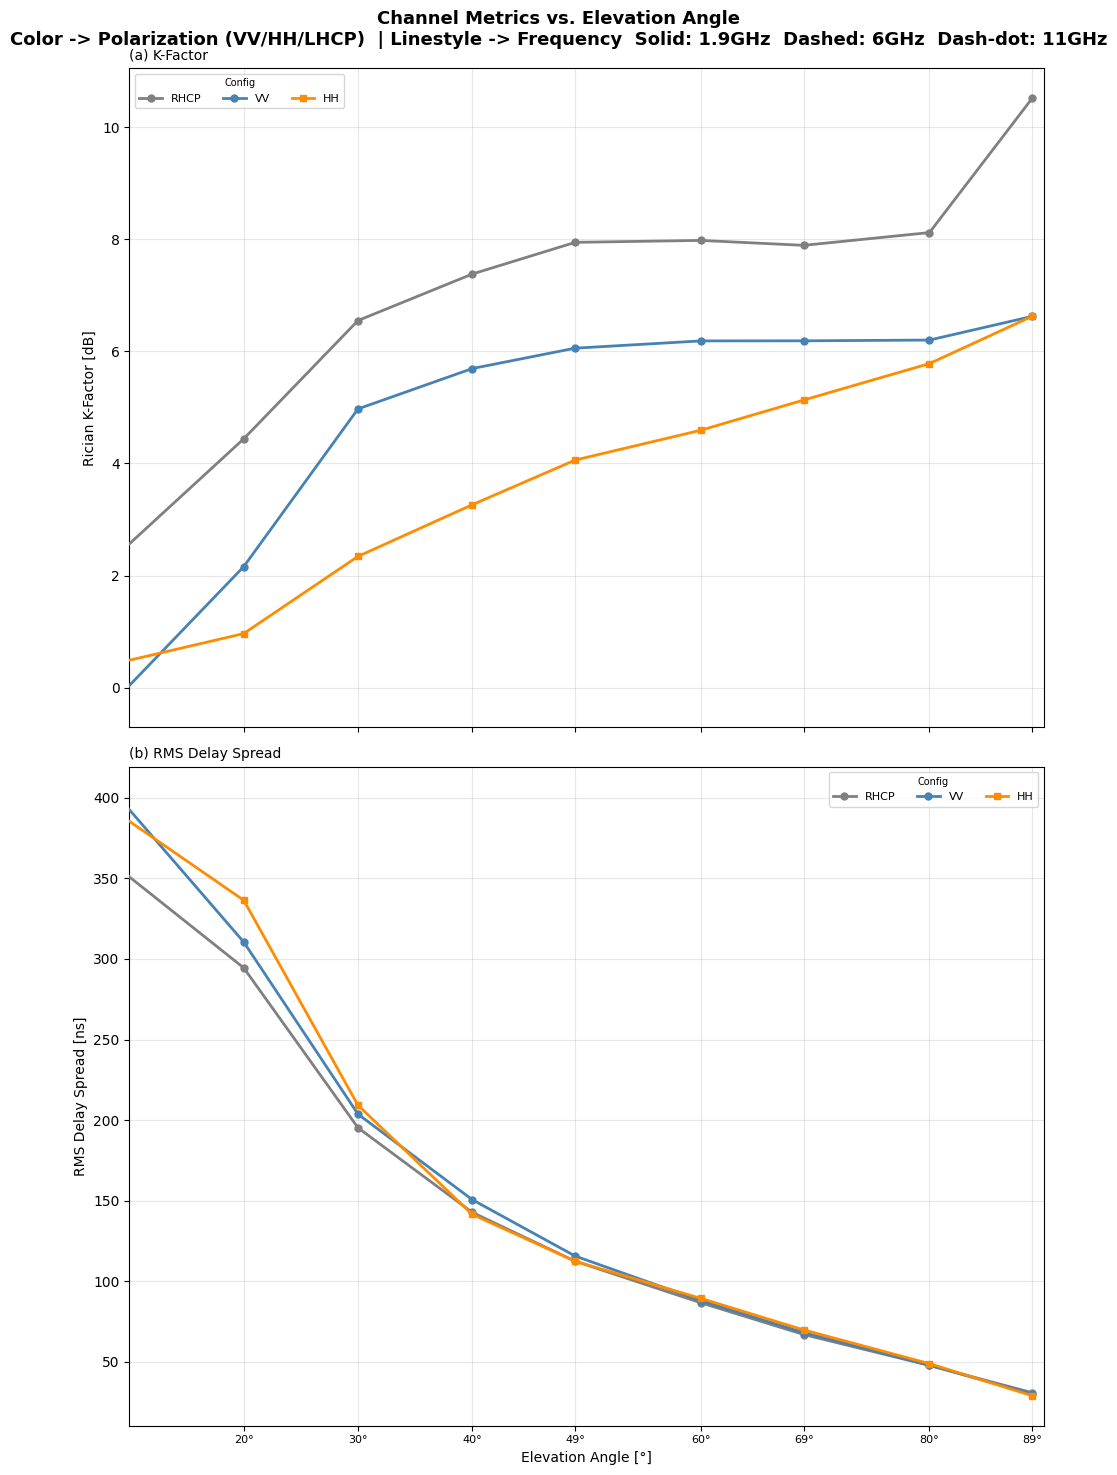

Saved -> ./figures_analysis/fig6_metrics_vs_elevation_multi_config.png
Saved -> ./figures_analysis/fig6_metrics_vs_elevation_multi_config.csv


In [5]:
configs_results = {}
for label, out_dir in OUTPUT_DIRS.items():
    print(f"  {label}  ({out_dir})")
    ar = load_all_results(out_dir, ELEVATION_ANGLES)
    if not ar:
        print(f"    WARNING: no results found — skipping")
    configs_results[label] = ar

_non_empty = {k: v for k, v in configs_results.items() if v}
if _non_empty:
    fig = plot_metrics_vs_elevation_multi_config(
        _non_empty,
        marker_every = 1,
        figsize      = (10, 15),
    )
    fig.axes[-1].set_xlim(10, 90)
    _fname = os.path.join(FIG_DIR, "fig6_metrics_vs_elevation_multi_config.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    _csv_fname = os.path.join(FIG_DIR, "fig6_metrics_vs_elevation_multi_config.csv")
    export_metrics_vs_elevation_multi_config_csv(_non_empty, _csv_fname)
    plt.show()
    print(f"Saved -> {_fname}")
    print(f"Saved -> {_csv_fname}")
else:
    print("No multi-config results found — check OUTPUT_DIRS paths.")

## 13 — CIR Viewer

Set `CIR_ELEV` to the elevation angle and `CIR_RX_IDX` to `'best_los'`,
`'worst_los'`, or an integer raw-result index.

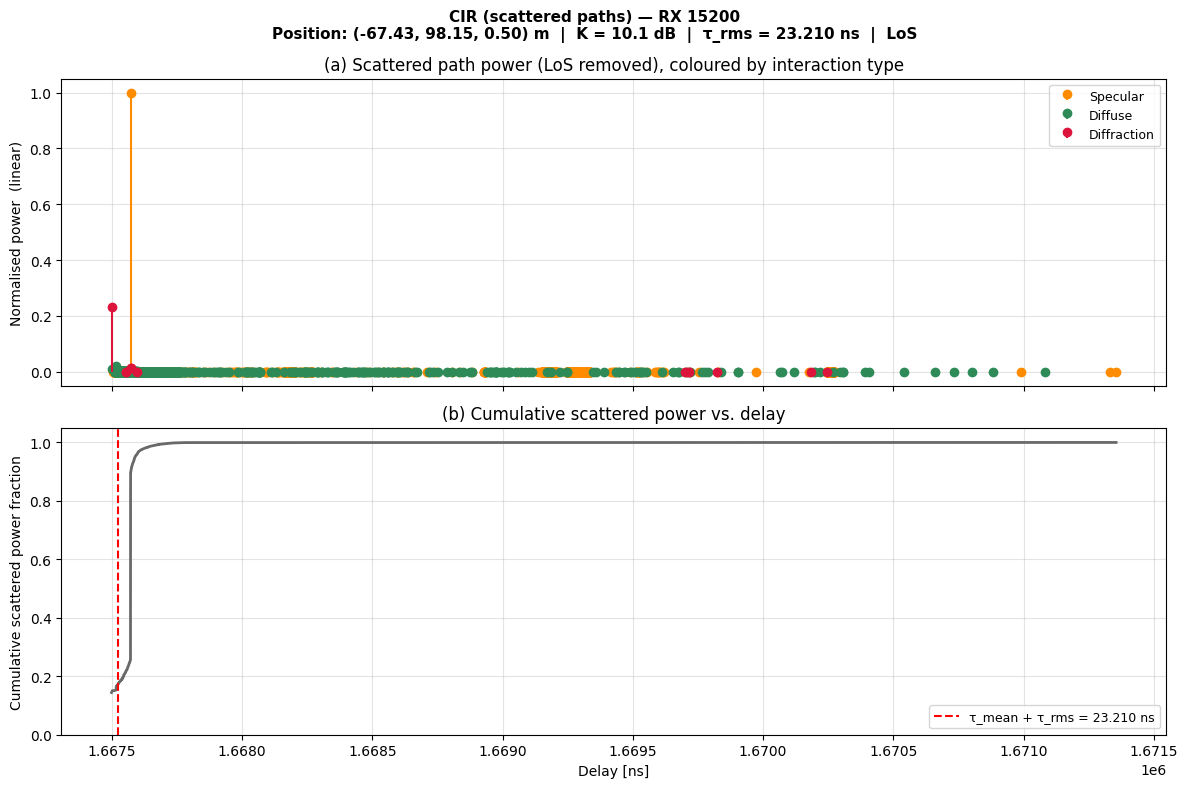

Saved -> ./figures_analysis/cir_elev010deg_rx15200.png
Paths: 2647  |  LoS: 1  |  Scatter: 2646


In [14]:
import importlib, plot_utils as _pu
importlib.reload(_pu)
from plot_utils import plot_cir

CIR_ELEV   = sorted(all_results.keys())[0]   # elevation angle to inspect
CIR_RX_IDX = "best_los"                       # 'best_los' | 'worst_los' | int

_res = all_results[CIR_ELEV]
_raw = _res["raw_results"]

if not _raw:
    print("No raw_results — lower RAW_SAVE_INTERVAL and re-run the simulation.")
else:
    _K_pr   = np.array(_res["K_power_ratio"])
    _tau_ns = np.array(_res["tau_rms_mean_s"]) * 1e9
    _K_dB   = 10 * np.log10(_K_pr + 1e-12)
    _rx_pos = np.array(_res["nominal_rx_positions"])

    if CIR_RX_IDX == "best_los":
        _cands = [r for r in _raw if r.get("has_los")] or _raw
        _r = max(_cands, key=lambda r: r["P_los"] / (r["P_scat"] + 1e-30))
    elif CIR_RX_IDX == "worst_los":
        _cands = [r for r in _raw if r.get("has_los")] or _raw
        _r = min(_cands, key=lambda r: r["P_los"] / (r["P_scat"] + 1e-30))
    else:
        _r = _raw[int(CIR_RX_IDX)]

    _nom    = np.array(_r["rx_nominal"])
    _rx_idx = int(np.argmin(np.linalg.norm(_rx_pos - _nom, axis=1)))

    fig = plot_cir(
        raw_result = _r,
        rx_idx     = _rx_idx,
        K_dB       = _K_dB[_rx_idx],
        tau_rms_ns = _tau_ns[_rx_idx],
    )
    _fname = os.path.join(FIG_DIR, f"cir_elev{int(CIR_ELEV):03d}deg_rx{_rx_idx+1}.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved -> {_fname}")
    _id0 = np.array(_r["inter_d0"])
    print(f"Paths: {len(_r['taus'])}  |  LoS: {int((_id0==0).sum())}  |  Scatter: {int((_id0!=0).sum())}")

## 14 — PDP Realization per Elevation

[checkpoint] Loaded results  elev=10.0°  n_rx=20000
[checkpoint] Loaded results  elev=20.0°  n_rx=20000
[checkpoint] Loaded results  elev=30.0°  n_rx=20000
[checkpoint] Loaded results  elev=40.0°  n_rx=20000
[checkpoint] Loaded results  elev=50.0°  n_rx=20000
[checkpoint] Loaded results  elev=60.0°  n_rx=20000
[checkpoint] Loaded results  elev=70.0°  n_rx=20000
[checkpoint] Loaded results  elev=80.0°  n_rx=20000


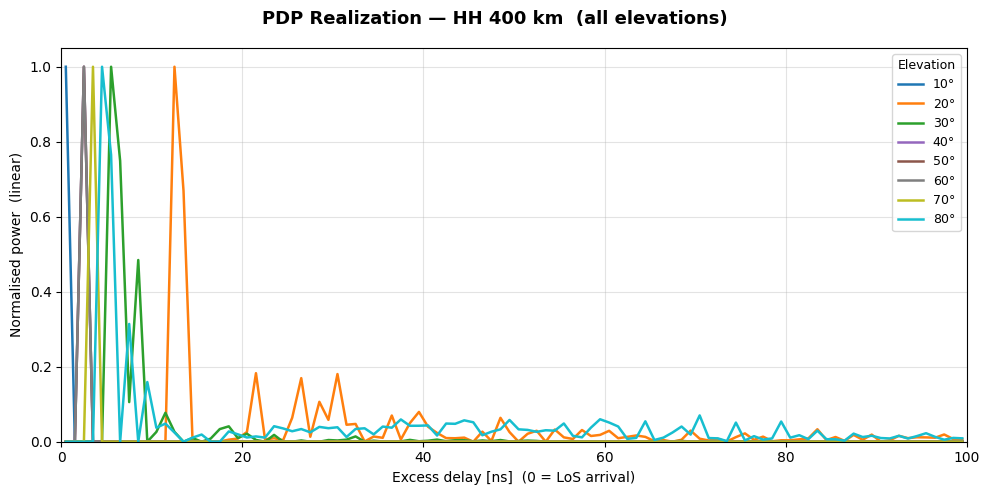

Saved -> ./figures_analysis/pdp_per_elevation_HH400km.png


In [15]:
# ── Load HH 400 km results ───────────────────────────────────────────────────
HH400_DIR = "./urban_env_results_400km_H"
pdp_results = load_all_results(HH400_DIR, ELEVATION_ANGLES)
if not pdp_results:
    print(f"No results found in {HH400_DIR} — check path.")
else:
    TYPE_NAMES  = {0: "LoS", 1: "Specular", 2: "Diffuse", 4: "Refraction", 8: "Diffraction"}

    angles_sorted = sorted(pdp_results.keys())
    colors = plt.cm.tab10(np.linspace(0, 1, len(angles_sorted)))

    BIN_NS   = 1.0    # delay bin width [ns]
    MAX_NS   = 100.0  # x-axis limit [ns]
    bins     = np.arange(0, MAX_NS + BIN_NS, BIN_NS)
    bin_ctrs = bins[:-1] + BIN_NS / 2

    fig, ax = plt.subplots(figsize=(10, 5))
    fig.suptitle("PDP Realization — HH 400 km  (all elevations)",
                 fontsize=13, fontweight="bold")

    for color, elev in zip(colors, angles_sorted):
        _res = pdp_results[elev]
        _raw = _res.get("raw_results", [])
        if not _raw:
            continue

        # Best LoS realization; fall back to first entry
        los_entries = [r for r in _raw if r.get("has_los", False)]
        r = (max(los_entries, key=lambda r: r["P_los"] / (r["P_scat"] + 1e-30))
             if los_entries else _raw[0])

        taus_all = np.asarray(r["taus"]) * 1e9
        pwr_all  = np.abs(np.asarray(r["amps"])) ** 2
        id0_all  = np.asarray(r["inter_d0"], dtype=int)

        # Excess delay (0 = LoS arrival), scattered paths only
        excess   = taus_all - taus_all.min()
        scat     = id0_all != 0
        excess_s = excess[scat]
        pwr_s    = pwr_all[scat]

        # Bin scattered power into 1 ns bins
        pwr_binned, _ = np.histogram(excess_s, bins=bins, weights=pwr_s)

        # Normalise to peak bin
        pwr_binned = pwr_binned / (pwr_binned.max() + 1e-300)

        ax.plot(bin_ctrs, pwr_binned, color=color, lw=1.8,
                label=f"{int(elev)}°")

    ax.set_xlim(0, MAX_NS)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Excess delay [ns]  (0 = LoS arrival)")
    ax.set_ylabel("Normalised power  (linear)")
    ax.legend(title="Elevation", fontsize=9, title_fontsize=9)
    ax.grid(True, alpha=0.35)

    plt.tight_layout()
    _fname = os.path.join(FIG_DIR, "pdp_per_elevation_HH400km.png")
    fig.savefig(_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved -> {_fname}")
